# EDA — Predicción de Severidad de Accidentes de Tránsito
**Curso:** Machine Learning Applied — Entrega 1

**Autores:** Jose [Apellido], Santiago Alvarez Peña

**Dataset:** Road Traffic Accident Dataset of Addis Ababa City (Kaggle: `saurabhshahane/road-traffic-accidents`)

Este notebook contiene el análisis exploratorio completo que respalda las cifras reportadas en el short-paper. Se trabaja con dos versiones del dataset: `RTA_Dataset.csv` (32 columnas, crudo, con nulos) y `cleaned.csv` (15 columnas, ya depurado, target codificado numéricamente).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)
raw = pd.read_csv('RTA_Dataset.csv')
clean = pd.read_csv('cleaned.csv')
raw.shape, clean.shape

((12316, 32), (12316, 15))

## 1. Estructura general del dataset crudo

In [2]:
raw.head()

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,Defect_of_vehicle,Area_accident_occured,Lanes_or_Medians,Road_allignment,Types_of_Junction,Road_surface_type,Road_surface_conditions,Light_conditions,Weather_conditions,Type_of_collision,Number_of_vehicles_involved,Number_of_casualties,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,No defect,Residential areas,NaN,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside-parked vehicles,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,No defect,Office areas,Undivided Two way,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,No defect,Recreational areas,other,NaN,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside objects,2,2,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,No defect,Office areas,other,Tangent road with mild grade and flat terrain,Y Shape,Earth roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,No defect,Industrial areas,other,Tangent road with flat terrain,Y Shape,Asphalt roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Time                         12316 non-null  str  
 1   Day_of_week                  12316 non-null  str  
 2   Age_band_of_driver           12316 non-null  str  
 3   Sex_of_driver                12316 non-null  str  
 4   Educational_level            11575 non-null  str  
 5   Vehicle_driver_relation      11737 non-null  str  
 6   Driving_experience           11487 non-null  str  
 7   Type_of_vehicle              11366 non-null  str  
 8   Owner_of_vehicle             11834 non-null  str  
 9   Service_year_of_vehicle      8388 non-null   str  
 10  Defect_of_vehicle            7889 non-null   str  
 11  Area_accident_occured        12077 non-null  str  
 12  Lanes_or_Medians             11931 non-null  str  
 13  Road_allignment              12174 non-null  str  
 14  T

**Observación:** el dataset crudo tiene 12,316 filas y 32 columnas, en su mayoría categóricas (`object`). Varias columnas tienen un número considerable de valores nulos, que se cuantifican a continuación.

## 2. Análisis de valores faltantes

In [4]:
missing_pct = (raw.isnull().mean() * 100).round(1).sort_values(ascending=False)
missing_pct[missing_pct > 0]

Defect_of_vehicle          35.9
Service_year_of_vehicle    31.9
Work_of_casuality          26.0
Fitness_of_casuality       21.4
Type_of_vehicle             7.7
Types_of_Junction           7.2
Driving_experience          6.7
Educational_level           6.0
Vehicle_driver_relation     4.7
Owner_of_vehicle            3.9
Lanes_or_Medians            3.1
Vehicle_movement            2.5
Area_accident_occured       1.9
Road_surface_type           1.4
Type_of_collision           1.3
Road_allignment             1.2
dtype: float64

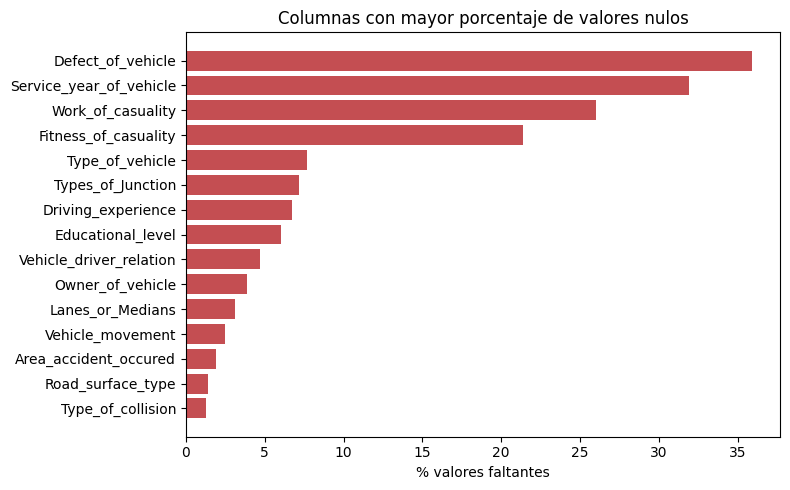

In [5]:
fig, ax = plt.subplots(figsize=(8,5))
top_missing = missing_pct[missing_pct > 0].head(15)
ax.barh(top_missing.index[::-1], top_missing.values[::-1], color='#C44E52')
ax.set_xlabel('% valores faltantes')
ax.set_title('Columnas con mayor porcentaje de valores nulos')
plt.tight_layout()
plt.show()

**Observación:** las columnas `Defect_of_vehicle` (35.9%), `Service_year_of_vehicle` (31.9%), `Work_of_casuality` (26.0%) y `Fitness_of_casuality` (21.4%) superan el 20% de valores faltantes. Estas columnas se excluyeron de la versión depurada (`cleaned.csv`) en lugar de imputarlas, dado el alto porcentaje de información ausente, que haría poco confiable cualquier imputación.

## 3. Verificación de la limpieza (`cleaned.csv`)

In [6]:
clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Age_band_of_driver       12316 non-null  str  
 1   Sex_of_driver            12316 non-null  str  
 2   Educational_level        12316 non-null  str  
 3   Vehicle_driver_relation  12316 non-null  str  
 4   Driving_experience       12316 non-null  str  
 5   Lanes_or_Medians         12316 non-null  str  
 6   Types_of_Junction        12316 non-null  str  
 7   Road_surface_type        12316 non-null  str  
 8   Light_conditions         12316 non-null  str  
 9   Weather_conditions       12316 non-null  str  
 10  Type_of_collision        12316 non-null  str  
 11  Vehicle_movement         12316 non-null  str  
 12  Pedestrian_movement      12316 non-null  str  
 13  Cause_of_accident        12316 non-null  str  
 14  Accident_severity        12316 non-null  int64
dtypes: int64(1), 

In [7]:
clean.isnull().sum().sum()  # confirmar cero nulos

np.int64(0)

**Observación:** la versión depurada conserva 15 variables categóricas relacionadas con el conductor, el vehículo, la vía y el entorno, y no contiene valores nulos. El target `Accident_severity` fue codificado numéricamente: `0 = Fatal injury`, `1 = Serious Injury`, `2 = Slight Injury`.

## 4. Distribución de la variable objetivo (hallazgo A)

In [8]:
sev_map = {0: 'Fatal', 1: 'Serious', 2: 'Slight'}
clean['sev_label'] = clean['Accident_severity'].map(sev_map)

counts = clean['sev_label'].value_counts()
pct = clean['sev_label'].value_counts(normalize=True).round(4) * 100
pd.DataFrame({'n': counts, '%': pct})

,n,%
sev_label,,
Slight,10415,84.56
Serious,1743,14.15
Fatal,158,1.28


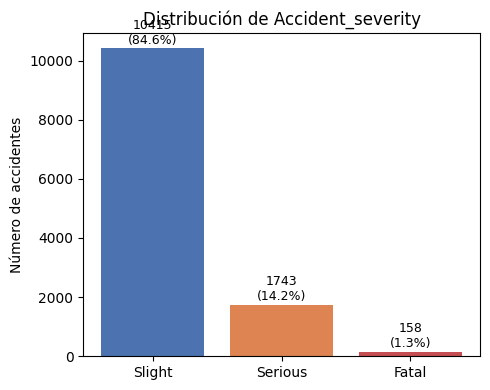

In [9]:
order = ['Slight', 'Serious', 'Fatal']
counts_ord = clean['sev_label'].value_counts().reindex(order)

fig, ax = plt.subplots(figsize=(5,4))
ax.bar(order, counts_ord.values, color=['#4C72B0', '#DD8452', '#C44E52'])
for i, v in enumerate(counts_ord.values):
    ax.text(i, v + 150, f'{v}\n({v/len(clean)*100:.1f}%)', ha='center', fontsize=9)
ax.set_title('Distribución de Accident_severity')
ax.set_ylabel('Número de accidentes')
plt.tight_layout()
plt.show()

**Observación clave (Hallazgo A — reportado en el paper, Sección VI.A y Tabla II):** el dataset está fuertemente desbalanceado: **84.6%** de los accidentes son de severidad leve (Slight), **14.2%** graves (Serious) y solo **1.3%** fatales (Fatal). Esto confirma que el problema debe tratarse como una clasificación multiclase desbalanceada, y que la Entrega 2 deberá usar métricas como F1-macro o recall por clase, y considerar técnicas de remuestreo (SMOTE, class weights).

## 5. Condiciones de luz vs. severidad (hallazgo B)

In [10]:
ct_light = pd.crosstab(clean['Light_conditions'], clean['sev_label'], normalize='index') * 100
ct_light['n'] = clean['Light_conditions'].value_counts()
ct_light['Serious+Fatal'] = ct_light['Serious'] + ct_light['Fatal']
ct_light.sort_values('Serious+Fatal', ascending=False).round(1)

sev_label,Fatal,Serious,Slight,n,Serious+Fatal
Light_conditions,,,,,
Darkness - no lighting,2.6,25.5,71.9,192,28.1
Darkness - lights unlit,0.0,17.5,82.5,40,17.5
Darkness - lights lit,2.0,14.2,83.8,3286,16.2
Daylight,1.0,13.9,85.1,8798,14.9


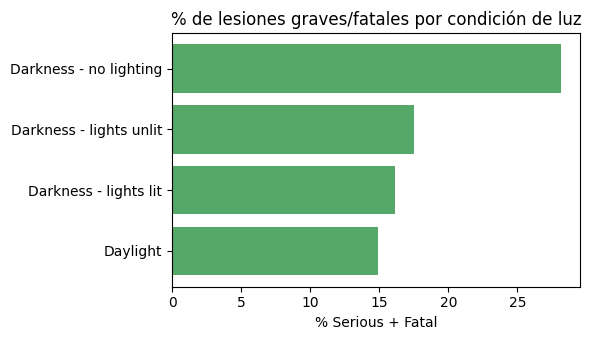

In [11]:
ct_sorted = ct_light.sort_values('Serious+Fatal')
fig, ax = plt.subplots(figsize=(6,3.5))
ax.barh(ct_sorted.index, ct_sorted['Serious+Fatal'], color='#55A868')
ax.set_xlabel('% Serious + Fatal')
ax.set_title('% de lesiones graves/fatales por condición de luz')
plt.tight_layout()
plt.show()

**Observación clave (Hallazgo B — reportado en el paper, Sección VI.B):** los accidentes ocurridos en **'Darkness - no lighting'** (oscuridad sin alumbrado) tienen **28.1%** de probabilidad de terminar en lesión grave o fatal, casi el doble que los accidentes en **'Daylight'** (**14.9%**). Esto sugiere que la iluminación de la vía es un predictor relevante de la severidad.

## 6. Causa del accidente vs. severidad (hallazgo C)

In [12]:
ct_cause = pd.crosstab(clean['Cause_of_accident'], clean['sev_label'], normalize='index') * 100
ct_cause['n'] = clean['Cause_of_accident'].value_counts()
ct_cause['Serious+Fatal'] = ct_cause['Serious'] + ct_cause['Fatal']
ct_cause.sort_values('Serious+Fatal', ascending=False).round(1).head(10)

sev_label,Fatal,Serious,Slight,n,Serious+Fatal
Cause_of_accident,,,,,
Overspeed,1.6,24.6,73.8,61,26.2
Overloading,3.4,16.9,79.7,59,20.3
Driving to the left,1.4,18.7,79.9,284,20.1
Driving at high speed,1.1,17.8,81.0,174,19.0
Overtaking,0.9,17.4,81.6,430,18.4
Overturning,1.3,15.4,83.2,149,16.8
Moving Backward,2.3,14.2,83.5,1137,16.5
Driving carelessly,1.6,14.9,83.5,1402,16.5
Getting off the vehicle improperly,1.5,14.7,83.8,197,16.2


**Observación clave (Hallazgo C — reportado en el paper, Sección VI.C):** causas como **'Overspeed'** y **'Overloading'** presentan proporciones de lesiones graves/fatales de aproximadamente **20%**, por encima del promedio general (~15.5%), lo que respalda incluir la causa del accidente como variable predictora clave.

### 6.1 Complemento: tipo de cruce vial vs. severidad

In [13]:
ct_junction = pd.crosstab(clean['Types_of_Junction'], clean['sev_label'], normalize='index') * 100
ct_junction['n'] = clean['Types_of_Junction'].value_counts()
ct_junction['Serious+Fatal'] = ct_junction['Serious'] + ct_junction['Fatal']
ct_junction.sort_values('Serious+Fatal', ascending=False).round(1)

sev_label,Fatal,Serious,Slight,n,Serious+Fatal
Types_of_Junction,,,,,
Other,0.4,18.7,80.9,445,19.1
Unknown,1.8,15.6,82.7,1078,17.3
No junction,1.9,15.1,83.0,3837,17.0
O Shape,0.6,15.9,83.5,164,16.5
Y Shape,1.2,13.9,84.9,4543,15.1
Crossing,0.6,11.3,88.2,2177,11.8
T Shape,0.0,11.7,88.3,60,11.7
X Shape,0.0,0.0,100.0,12,0.0


**Observación:** los accidentes en vías sin ningún tipo de cruce regulado (`No junction`) muestran una proporción de lesiones graves/fatales (17.0%) mayor que en cruces peatonales señalizados (`Crossing`, 11.8%), un patrón más leve que sugiere un posible efecto protector de la señalización vial, mencionado como observación adicional en el paper (Sección VI.C).

## 7. Conclusión del EDA

El dataset tiene tamaño y calidad suficientes (tras la depuración) para plantear el problema como una tarea de clasificación supervisada multiclase. El reto metodológico principal identificado para la Entrega 2 es el fuerte desbalance de clases, especialmente la escasez de la clase `Fatal` (1.3% de los registros), que es también la de mayor interés práctico.